In [ ]:
import pandas as pd
df = pd.read_csv('觀光遊憩據點按縣市及遊憩據點交叉分析.csv')  # 讀取文件
#df.describe()  # 輸出基礎統計信息
df.head(5)

,縣市,Unnamed: 1,遊憩據點,Unnamed: 3,108年7月,108年8月,108年9月,108年10月,108年11月,108年12月,...,112年11月,112年12月,113年1月,113年2月,113年3月,113年4月,113年5月,113年6月,113年7月,小計
0,NaN,Location,NaN,Scenic Spots,2019/7,2019/8,2019/9,2019/10,2019/11,2019/12,...,2023/11,2023/12,2024/1,2024/2,2024/3,2024/4,2024/5,2024/6,2024/7,Total
1,臺東縣,Taitung County,東部海岸富岡地質公園及加路蘭休憩區,East Coast Fugang Geopark And Jialulan Recreat...,65771,51654,47709,76751,40976,40877,...,41079,46334,250299,325808,295242,227590,288382,279951,313015,4891011
2,臺東縣,Taitung County,三仙台遊憩區及周邊地區,Sanxiantai recreation area and surrounding areas,64872,52134,40093,56200,45216,40454,...,32781,27492,125682,217132,155958,107730,116275,125704,146359,2994488
3,臺東縣,Taitung County,八仙洞遊憩區,Baxian Caves Recreation Area,11551,9482,11625,11476,8815,6124,...,5730,4576,24792,36927,27668,16360,22334,22540,25166,531848
4,臺東縣,Taitung County,綠島遊憩區,Lyudao（Green Island）Recreation Area,66709,35395,36840,28644,9990,6231,...,7542,6252,6080,9623,11879,27941,32058,39747,37916,1483565


In [ ]:
# 刪除第0列，假設是包含欄位名錯誤行的地方
df_cleaned = df.drop(0)

# 查看是否還有 NaN 值的列，刪除包含 NaN 的列（如果需要）
df_cleaned = df_cleaned.dropna(how='all')  # 刪除全是 NaN 的列

# 如果有些欄的 NaN 可以忽略，僅刪除特定欄位的 NaN（如 '縣市' 和 '遊憩據點'）
df_cleaned = df_cleaned.dropna(subset=['縣市', '遊憩據點'])

# 查看清理後的數據
print(df_cleaned.head())

df = df_cleaned
df.head(5)

    縣市      Unnamed: 1               遊憩據點  \
1  臺東縣  Taitung County  東部海岸富岡地質公園及加路蘭休憩區   
2  臺東縣  Taitung County        三仙台遊憩區及周邊地區   
3  臺東縣  Taitung County             八仙洞遊憩區   
4  臺東縣  Taitung County              綠島遊憩區   
5  臺東縣  Taitung County          鹿野高臺及周邊地區   

                                          Unnamed: 3  108年7月  108年8月 108年9月  \
1  East Coast Fugang Geopark And Jialulan Recreat...   65771   51654  47709   
2   Sanxiantai recreation area and surrounding areas   64872   52134  40093   
3                       Baxian Caves Recreation Area   11551    9482  11625   
4                Lyudao（Green Island）Recreation Area   66709   35395  36840   
5           Luyeh high terrace and surrounding areas  199337  117804  45159   

  108年10月 108年11月 108年12月  ... 112年11月 112年12月  113年1月  113年2月  113年3月  \
1   76751   40976   40877  ...   41079   46334  250299  325808  295242   
2   56200   45216   40454  ...   32781   27492  125682  217132  155958   
3   11476    8815    6124  ...  

,縣市,Unnamed: 1,遊憩據點,Unnamed: 3,108年7月,108年8月,108年9月,108年10月,108年11月,108年12月,...,112年11月,112年12月,113年1月,113年2月,113年3月,113年4月,113年5月,113年6月,113年7月,小計
1,臺東縣,Taitung County,東部海岸富岡地質公園及加路蘭休憩區,East Coast Fugang Geopark And Jialulan Recreat...,65771,51654,47709,76751,40976,40877,...,41079,46334,250299,325808,295242,227590,288382,279951,313015,4891011
2,臺東縣,Taitung County,三仙台遊憩區及周邊地區,Sanxiantai recreation area and surrounding areas,64872,52134,40093,56200,45216,40454,...,32781,27492,125682,217132,155958,107730,116275,125704,146359,2994488
3,臺東縣,Taitung County,八仙洞遊憩區,Baxian Caves Recreation Area,11551,9482,11625,11476,8815,6124,...,5730,4576,24792,36927,27668,16360,22334,22540,25166,531848
4,臺東縣,Taitung County,綠島遊憩區,Lyudao（Green Island）Recreation Area,66709,35395,36840,28644,9990,6231,...,7542,6252,6080,9623,11879,27941,32058,39747,37916,1483565
5,臺東縣,Taitung County,鹿野高臺及周邊地區,Luyeh high terrace and surrounding areas,199337,117804,45159,51951,42533,46205,...,30339,20427,125601,125435,117725,84897,86501,96844,170764,4729290


## 時間序列分析：

- 分析每個月的遊客數趨勢，使用 plot() 進行可視化展示。
- 例如，繪製特定景點在不同年份的遊客數變化趨勢。

In [ ]:
# Colab 進行matplotlib繪圖時顯示繁體中文
# 下載台北思源黑體並命名taipei_sans_tc_beta.ttf，移至指定路徑
!wget -O TaipeiSansTCBeta-Regular.ttf https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download

import matplotlib

# 改style要在改font之前
# plt.style.use('seaborn')

matplotlib.font_manager.fontManager.addfont('TaipeiSansTCBeta-Regular.ttf')
matplotlib.rc('font', family='Taipei Sans TC Beta')

--2024-10-11 03:28:37--  https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_
Resolving drive.google.com (drive.google.com)... 172.253.115.100, 172.253.115.139, 172.253.115.113, ...
Connecting to drive.google.com (drive.google.com)|172.253.115.100|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_ [following]
--2024-10-11 03:28:37--  https://drive.usercontent.google.com/download?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 172.253.62.132, 2607:f8b0:4004:c07::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|172.253.62.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 20659344 (20M) [application/octet-stream]
Saving to: ‘TaipeiSansTCBeta-Regular.ttf’

TaipeiSansTCBeta-Re 100%[===================>]  19.70M  --.-KB/s    in 0.1s    

2024-10-11 03

In [ ]:
df.set_index('遊憩據點', inplace=True)  # 設置景點名稱為索引
df.head(5)

,縣市,Unnamed: 1,Unnamed: 3,108年7月,108年8月,108年9月,108年10月,108年11月,108年12月,109年1月,...,112年11月,112年12月,113年1月,113年2月,113年3月,113年4月,113年5月,113年6月,113年7月,小計
遊憩據點,,,,,,,,,,,,,,,,,,,,,
東部海岸富岡地質公園及加路蘭休憩區,臺東縣,Taitung County,East Coast Fugang Geopark And Jialulan Recreat...,65771,51654,47709,76751,40976,40877,91235,...,41079,46334,250299,325808,295242,227590,288382,279951,313015,4891011
三仙台遊憩區及周邊地區,臺東縣,Taitung County,Sanxiantai recreation area and surrounding areas,64872,52134,40093,56200,45216,40454,57901,...,32781,27492,125682,217132,155958,107730,116275,125704,146359,2994488
八仙洞遊憩區,臺東縣,Taitung County,Baxian Caves Recreation Area,11551,9482,11625,11476,8815,6124,14833,...,5730,4576,24792,36927,27668,16360,22334,22540,25166,531848
綠島遊憩區,臺東縣,Taitung County,Lyudao（Green Island）Recreation Area,66709,35395,36840,28644,9990,6231,12699,...,7542,6252,6080,9623,11879,27941,32058,39747,37916,1483565
鹿野高臺及周邊地區,臺東縣,Taitung County,Luyeh high terrace and surrounding areas,199337,117804,45159,51951,42533,46205,64624,...,30339,20427,125601,125435,117725,84897,86501,96844,170764,4729290


<Axes: >

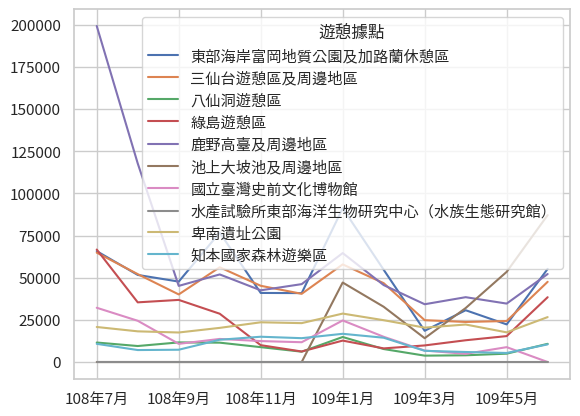

In [ ]:

#df.T.plot()  # 畫出時間序列圖，按月展示各景點的遊客數

# 選出想要的欄位與景點，從第3欄開始是人數值的欄位
df_numeric = df.iloc[:10, 3:3+12]  # 選擇數值列

# 將字串轉換為數值，強制轉換錯誤項為 NaN
df_numeric = df_numeric.apply(pd.to_numeric, errors='coerce')

# 處理缺失值，例如用 0 填充
df_numeric.fillna(0, inplace=True)

# 將數據轉置並繪製圖表
df_numeric.T.plot()

## 按年匯總遊客數：

- 匯總各景點每年的總遊客數，查看哪個年份的遊客最多。
- 可以通過篩選列名和 groupby() 方法按年份分組。

In [ ]:
# 將中華民國年份轉換為公歷年份，並使用 pd.to_datetime 進行日期解析
def convert_to_gregorian(date_str):
    #print(date_str)
    date_str = date_str.strip('月')
    year_str, month_str = date_str.split('年')
    roc_year = int(year_str)  # 中華民國年份
    gregorian_year = roc_year + 1911  # 轉換為公歷年
    #print(f'{gregorian_year}年{month_str}月')
    return f'{gregorian_year}/{month_str}'

# 轉換列名中的中華民國年為公歷年
new_columns = [convert_to_gregorian(col) for col in df.columns[3:-1]]

# 將轉換後的年份設置為列名
df.columns = list(df.columns[:3]) + new_columns + list(df.columns[-1:])

# 查看結果
df.head(5)



,縣市,Unnamed: 1,Unnamed: 3,2019/7,2019/8,2019/9,2019/10,2019/11,2019/12,2020/1,...,2023/11,2023/12,2024/1,2024/2,2024/3,2024/4,2024/5,2024/6,2024/7,小計
遊憩據點,,,,,,,,,,,,,,,,,,,,,
東部海岸富岡地質公園及加路蘭休憩區,臺東縣,Taitung County,East Coast Fugang Geopark And Jialulan Recreat...,65771,51654,47709,76751,40976,40877,91235,...,41079,46334,250299,325808,295242,227590,288382,279951,313015,4891011
三仙台遊憩區及周邊地區,臺東縣,Taitung County,Sanxiantai recreation area and surrounding areas,64872,52134,40093,56200,45216,40454,57901,...,32781,27492,125682,217132,155958,107730,116275,125704,146359,2994488
八仙洞遊憩區,臺東縣,Taitung County,Baxian Caves Recreation Area,11551,9482,11625,11476,8815,6124,14833,...,5730,4576,24792,36927,27668,16360,22334,22540,25166,531848
綠島遊憩區,臺東縣,Taitung County,Lyudao（Green Island）Recreation Area,66709,35395,36840,28644,9990,6231,12699,...,7542,6252,6080,9623,11879,27941,32058,39747,37916,1483565
鹿野高臺及周邊地區,臺東縣,Taitung County,Luyeh high terrace and surrounding areas,199337,117804,45159,51951,42533,46205,64624,...,30339,20427,125601,125435,117725,84897,86501,96844,170764,4729290


In [ ]:
# 假設 df 是你的數據
# 重置索引以便於使用 melt
df.reset_index(inplace=True)
df.head(5)

,遊憩據點,縣市,Unnamed: 1,Unnamed: 3,2019/7,2019/8,2019/9,2019/10,2019/11,2019/12,...,2023/11,2023/12,2024/1,2024/2,2024/3,2024/4,2024/5,2024/6,2024/7,小計
0,東部海岸富岡地質公園及加路蘭休憩區,臺東縣,Taitung County,East Coast Fugang Geopark And Jialulan Recreat...,65771,51654,47709,76751,40976,40877,...,41079,46334,250299,325808,295242,227590,288382,279951,313015,4891011
1,三仙台遊憩區及周邊地區,臺東縣,Taitung County,Sanxiantai recreation area and surrounding areas,64872,52134,40093,56200,45216,40454,...,32781,27492,125682,217132,155958,107730,116275,125704,146359,2994488
2,八仙洞遊憩區,臺東縣,Taitung County,Baxian Caves Recreation Area,11551,9482,11625,11476,8815,6124,...,5730,4576,24792,36927,27668,16360,22334,22540,25166,531848
3,綠島遊憩區,臺東縣,Taitung County,Lyudao（Green Island）Recreation Area,66709,35395,36840,28644,9990,6231,...,7542,6252,6080,9623,11879,27941,32058,39747,37916,1483565
4,鹿野高臺及周邊地區,臺東縣,Taitung County,Luyeh high terrace and surrounding areas,199337,117804,45159,51951,42533,46205,...,30339,20427,125601,125435,117725,84897,86501,96844,170764,4729290


In [ ]:
# 使用 melt 將 DataFrame 轉換為長表格形式
df_melted = df.melt(id_vars=['遊憩據點','縣市', 'Unnamed: 1', 'Unnamed: 3', '小計'],
                    var_name='日期', value_name='遊客數')

# 提取年份，並將其轉換為整數
df_melted['年份'] = pd.to_datetime(df_melted['日期'], format='%Y/%m', errors='coerce').dt.year

# 清理遊客數，去除空格，替換缺失值為0，並轉換為整數
df_melted['遊客數'] = df_melted['遊客數'].str.replace(' ', '').astype(float).fillna(0).astype(int)

df_melted


,遊憩據點,縣市,Unnamed: 1,Unnamed: 3,小計,日期,遊客數,年份
0,東部海岸富岡地質公園及加路蘭休憩區,臺東縣,Taitung County,East Coast Fugang Geopark And Jialulan Recreat...,4891011,2019/7,65771,2019
1,三仙台遊憩區及周邊地區,臺東縣,Taitung County,Sanxiantai recreation area and surrounding areas,2994488,2019/7,64872,2019
2,八仙洞遊憩區,臺東縣,Taitung County,Baxian Caves Recreation Area,531848,2019/7,11551,2019
3,綠島遊憩區,臺東縣,Taitung County,Lyudao（Green Island）Recreation Area,1483565,2019/7,66709,2019
4,鹿野高臺及周邊地區,臺東縣,Taitung County,Luyeh high terrace and surrounding areas,4729290,2019/7,199337,2019
...,...,...,...,...,...,...,...,...
2435,建功嶼,金門縣,Kinmen County,Jiangong Islet,43898,2024/7,6830,2024
2436,東引遊客中心,連江縣,Lienchiang County,Dongyin Visitor Center,108350,2024/7,3321,2024
2437,莒光遊客中心,連江縣,Lienchiang County,Juguang Visitor Center,154573,2024/7,3077,2024
2438,北竿遊客中心,連江縣,Lienchiang County,Beigan Visitor Center,331397,2024/7,7503,2024


`df.melt()` 是 Pandas 中的一個函數，用來將寬格式的數據轉換為長格式。在程式碼中：

```python
df_melted = df.melt(id_vars=['遊憩據點', '縣市', 'Unnamed: 1', 'Unnamed: 3'], var_name='日期', value_name='遊客數')
```

含義：

1. **`id_vars=['遊憩據點', '縣市', 'Unnamed: 1', 'Unnamed: 3']`**：表示這些列在轉換過程中保持不變（不進行「展開」）。這些列是每一行的固定標識符或屬性。

2. **`var_name='日期'`**：將原先的列名（如 '2019/7', '2019/8', ...）轉換為一個新的列，列名為「日期」。即把原來每個月的列名變成「日期」列中的值。

3. **`value_name='遊客數'`**：將原來每個月對應的遊客數值，變為「遊客數」列的值。

通過這段程式碼，你將原先以月份為列的數據轉換為以「日期」和「遊客數」為兩列的長格式。例如：

| 遊憩據點       | 縣市  | Unnamed: 1 | Unnamed: 3                                       | 日期      | 遊客數 |
|---------------|-------|------------|-------------------------------------------------|-----------|--------|
| 東部海岸富岡地質公園 | 臺東縣 | Taitung County | East Coast Fugang Geopark And Jialulan...        | 2019/7    | 65771  |
| 東部海岸富岡地質公園 | 臺東縣 | Taitung County | East Coast Fugang Geopark And Jialulan...        | 2019/8    | 51654  |


In [ ]:
# 按年份和縣市匯總遊客數
yearly_summary = df_melted.groupby(['年份', '縣市'])['遊客數'].sum().reset_index()

# 輸出年度遊客匯總
yearly_summary

,年份,縣市,遊客數
0,2019,澎湖縣,1078230
1,2019,臺東縣,2252138
2,2019,連江縣,104146
3,2019,金門縣,1259090
4,2020,澎湖縣,2297200
5,2020,臺東縣,5387399
6,2020,連江縣,195447
7,2020,金門縣,1567326
8,2021,澎湖縣,974258
9,2021,臺東縣,3341710


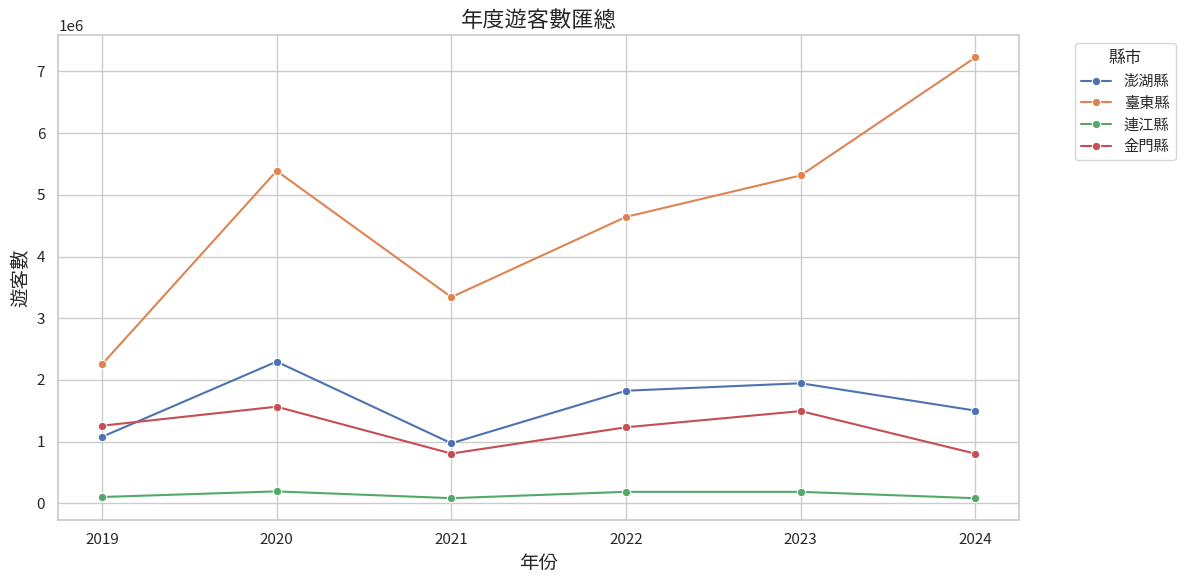

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 設置圖形風格
sns.set(style='whitegrid')

# 改style要在改font之前
matplotlib.font_manager.fontManager.addfont('TaipeiSansTCBeta-Regular.ttf')
matplotlib.rc('font', family='Taipei Sans TC Beta')

# 創建圖形
plt.figure(figsize=(12, 6))

# 使用 seaborn 的線性圖繪製每個縣市的年度遊客數
sns.lineplot(data=yearly_summary, x='年份', y='遊客數', hue='縣市', marker='o')

# 添加標題和標籤
plt.title('年度遊客數匯總', fontsize=16)
plt.xlabel('年份', fontsize=14)
plt.ylabel('遊客數', fontsize=14)
plt.xticks(yearly_summary['年份'].unique())  # 確保每個年份都顯示
plt.legend(title='縣市', bbox_to_anchor=(1.05, 1), loc='upper left')

# 顯示圖形
plt.tight_layout()
plt.show()

In [ ]:
# 按年度匯總每年的遊客數
df_yearly_summary = df_melted.groupby('年份')['遊客數'].sum().reset_index()

# 找出遊客數最多的年份
max_year = df_yearly_summary[df_yearly_summary['遊客數'] == df_yearly_summary['遊客數'].max()]

# 打印匯總結果和最多遊客的年份
print(df_yearly_summary)
print("遊客最多的年份是：")
print(max_year)

     年份      遊客數
0  2019  4693604
1  2020  9447372
2  2021  5209055
3  2022  7890222
4  2023  8945023
5  2024  9620428
遊客最多的年份是：
     年份      遊客數
5  2024  9620428


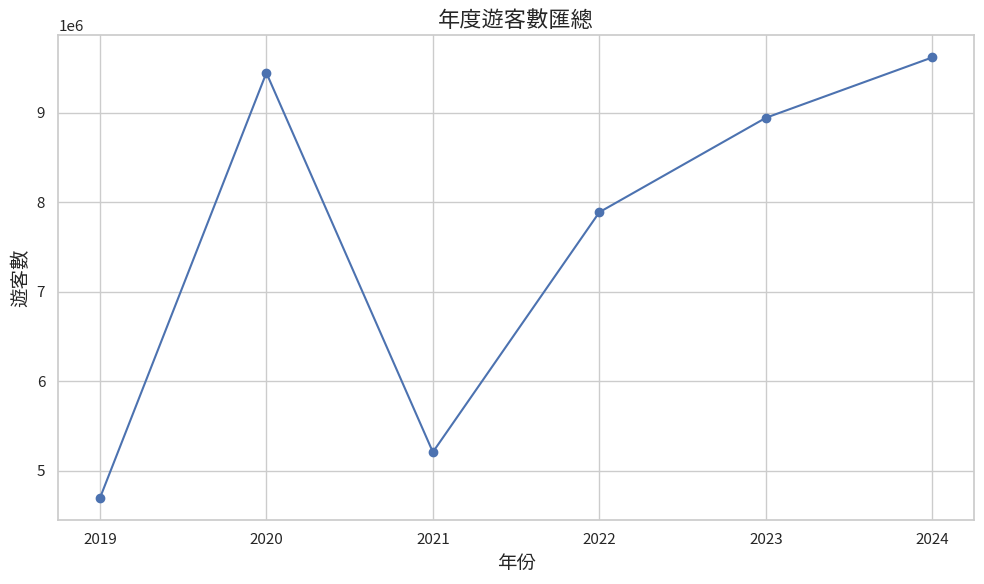

In [ ]:
# 創建圖形
plt.figure(figsize=(10, 6))

# 繪製折線圖
plt.plot(df_yearly_summary['年份'], df_yearly_summary['遊客數'], marker='o', linestyle='-', color='b')

# 添加標題和標籤
plt.title('年度遊客數匯總', fontsize=16)
plt.xlabel('年份', fontsize=14)
plt.ylabel('遊客數', fontsize=14)

# 設置 x 軸為整數年份
plt.xticks(df_yearly_summary['年份'].astype(int))

# 顯示網格
plt.grid(True)

# 顯示圖形
plt.tight_layout()
plt.show()

## 區域匯總：

- 匯總不同區域（如縣市）的遊客總數，查看哪個縣市的遊客最多。
- 使用 groupby() 函數按「縣市」進行分組統計。

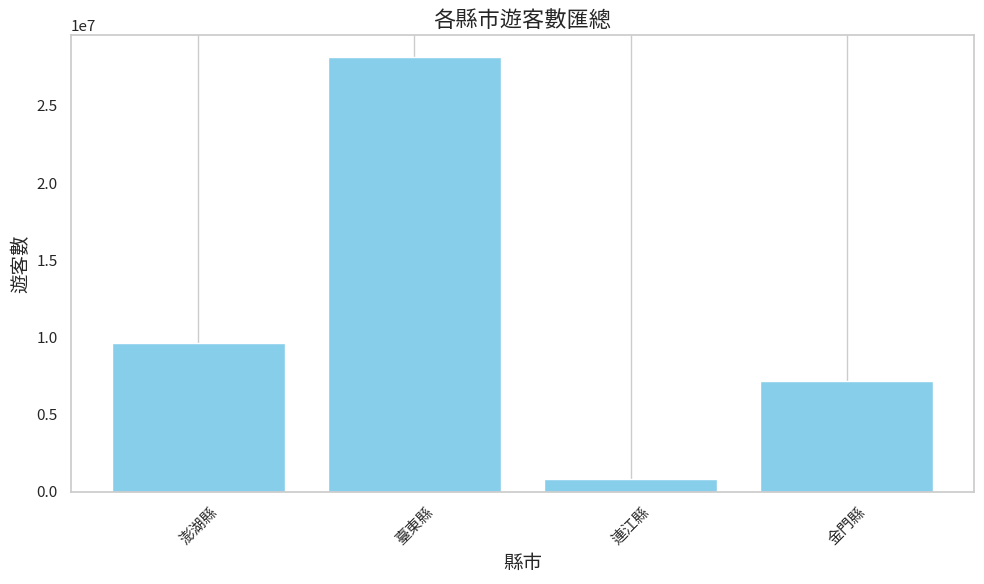

In [ ]:
# 將月份列轉換為數值並匯總
months = df.columns[3:-1]  # 獲取所有月份的列
df[months] = df[months].apply(pd.to_numeric, errors='coerce')  # 轉換為數值

# 按縣市匯總遊客數
county_summary = df.groupby('縣市')[months].sum().reset_index()

# 計算小計
county_summary['小計'] = county_summary[months].sum(axis=1)

# 創建圖形
plt.figure(figsize=(10, 6))

# 使用條形圖繪製每個縣市的遊客數總和
plt.bar(county_summary['縣市'], county_summary['小計'], color='skyblue')

# 添加標題和標籤
plt.title('各縣市遊客數匯總', fontsize=16)
plt.xlabel('縣市', fontsize=14)
plt.ylabel('遊客數', fontsize=14)

# 顯示網格
plt.grid(axis='y')

# 顯示圖形
plt.xticks(rotation=45)  # 旋轉 x 軸標籤以避免重疊
plt.tight_layout()
plt.show()

## 景點間的遊客差異分析：

- 比較各個景點在特定時間段內的遊客差異，可以使用箱線圖或柱狀圖進行可視化。

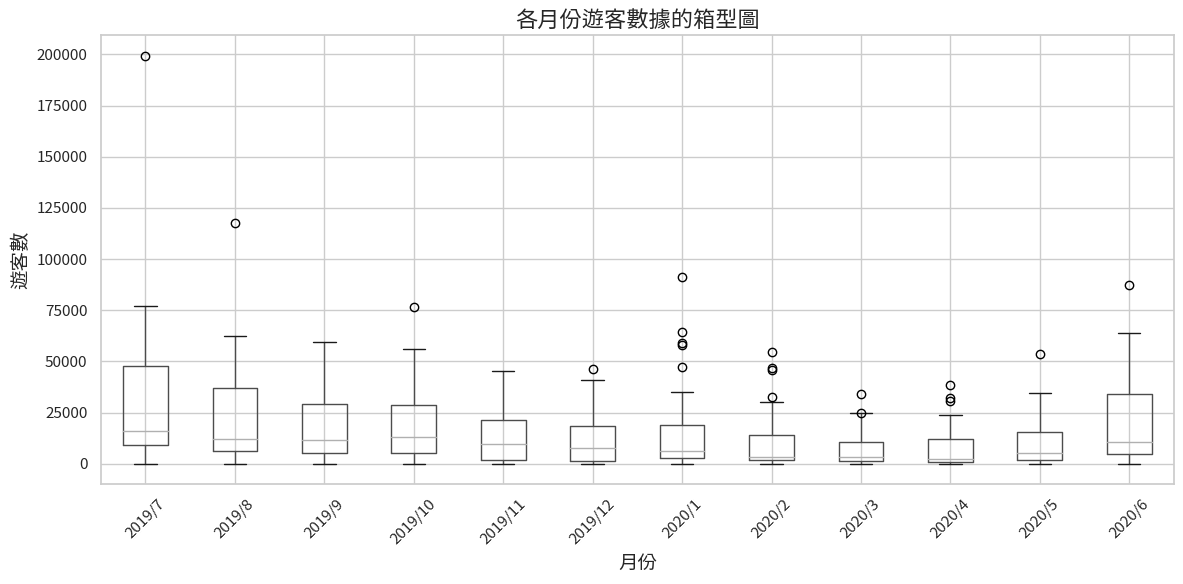

In [ ]:
# 繪製箱型圖
plt.figure(figsize=(12, 6))
df.boxplot(column=list(df.columns[4:4+12]))

# 添加標題和標籤
plt.title('各月份遊客數據的箱型圖', fontsize=16)
plt.xlabel('月份', fontsize=14)
plt.ylabel('遊客數', fontsize=14)

# 顯示圖形
plt.xticks(rotation=45)  # 旋轉 x 軸標籤
plt.tight_layout()
plt.show()

# 可以住哪裡？

In [ ]:
import json

with open('HotelList.json', 'r', encoding='utf-8-sig') as file:
    data = json.load(file)

# 將 JSON 轉換為 DataFrame
hotels_df = pd.json_normalize(data['Hotels'])

# 用戶輸入的城市名稱
user_input_city = input("請輸入城市名稱（例如：臺東縣）：")

# 篩選並列出相應的旅館名稱
matching_hotels = hotels_df[hotels_df['PostalAddress.City'] == user_input_city]

if not matching_hotels.empty:
    print("在", user_input_city, "的旅館有：")
    print(matching_hotels['HotelName'].to_string(index=False))
else:
    print("未找到", user_input_city, "的旅館。")


請輸入城市名稱（例如：臺東縣）：臺東縣
在 臺東縣 的旅館有：
               凱旋新宿商旅
               觀關嚮戶民宿
                克卜勒民宿
             初鹿生態農莊民宿
                 安德飯店
                 樂活民宿
               塔羅之昕民宿
               月光莊園民宿
                瑪拉松民宿
              艾蜜麗庭園別墅
                 東金民宿
                 雀屏山莊
                消防情民宿
               東糖29民宿
                 宛美民宿
               莊稼熟了參館
                比砂麓民宿
               椰林風情民宿
                嘟嘟好民宿
                三又木民宿
               台東四季民宿
               鴻瑞輕旅二館
             畫日風尚休閒會館
                 蘭舍民宿
               英惠原藝民宿
                佳美髮民宿
                紫亭賞民宿
               碧海青天民宿
              忘憂﹝如意﹞館
               馬卡巴嗨文創
               沐月心宿民宿
               睿凡的家民宿
             如意曙光渡假酒店
               地久天長民宿
                 甲穩民宿
                 建華旅社
                稻鄉海民宿
               筆令莊園民宿
                 明品民宿
              娜路彎銀河行館
                 櫻花民宿
             日安艸木公寓民宿
               托斯卡尼民宿
                 怡靜民宿


In [ ]:


# 用戶輸入的服務資訊關鍵字
user_input_service = input("請輸入想要的服務資訊關鍵字（例如：自行車友善）：")
matching_hotels_city = matching_hotels
# 進一步篩選包含服務資訊的旅館
matching_hotels = matching_hotels_city[
    matching_hotels_city['ServiceInfo'].str.contains(user_input_service, na=False)
]

if not matching_hotels.empty:
    print("在", user_input_city, "的符合條件的旅館有：")
    print(matching_hotels[['HotelName', 'ServiceInfo']].to_string(index=False))
else:
    print("未找到在", user_input_city, "符合服務資訊的旅館。")

請輸入想要的服務資訊關鍵字（例如：自行車友善）：自行車
在 臺東縣 的符合條件的旅館有：
        HotelName                                                                                                                                                                                         ServiceInfo
           凱旋新宿商旅                                                                                                                                                餐廳,無線網路,國民旅遊卡,停車場,,,,郵電服務,商務旅遊中心,自行車租借,AED,,,自行車友善旅宿
           觀關嚮戶民宿                                                                                                                                                                                             自行車友善旅宿
             樂活民宿                                                                                                                                                                          停車場,餐廳,有線網路,溫泉設施,,,自行車友善旅宿
           塔羅之昕民宿                                                                                  

In [ ]:

# 用戶輸入的預算範圍
user_input_budget = int(input("請輸入預算（例如：2500）："))

# 最後篩選符合預算範圍的旅館
final_matching_hotels = matching_hotels[
    (matching_hotels['LowestPrice'] <= user_input_budget) &
    (matching_hotels['CeilingPrice'] >= user_input_budget)
]

if not final_matching_hotels.empty:
    print("在", user_input_city, "的符合 ",user_input_service," 條件的旅館有：")
    print(final_matching_hotels[['HotelName','LowestPrice', 'CeilingPrice',  'ServiceInfo']].to_string(index=False))
else:
    print("未找到在", user_input_city, "符合服務資訊和預算的旅館。")

請輸入預算（例如：2500）：2500
在 臺東縣 的符合  自行車  條件的旅館有：
        HotelName  LowestPrice  CeilingPrice                                                                                                                                                                           ServiceInfo
          艾蜜麗庭園別墅         1500          3500                                                                                                                                                                               自行車友善旅宿
            消防情民宿         1500          4200                                                                                                                          無線網路,iTaiwan,國民旅遊卡,停車場,自助洗衣(免費),,,,洗衣服務,接送服務,自行車租借,,,自行車友善旅宿
            玉蟾園民宿         1800          3600                                                                                                                                          停車場,餐廳,有線網路,國民旅遊卡,,,自行車租借,導覽解說,體驗活動,,自行車友善旅宿
             諾園民宿         2500          5400    

## 有沒有可能再更進階一點呢？
- 這些資料即時自動從網站下載，而不用上傳呢？
- 與地圖搭配，直接把這些點顯示在地圖上呢？ (以上json原始資料有座標)
- 能否給他我的座標，直接篩選出離我最近的十間旅館呢？
